**Importing required libraries**

In [1]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
pickle_mapping = {
    'customer_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/customer_clean.pkl',
    'invent_movement_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/inventory_movement_clean.pkl',
    'lost_sales_log_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/lost_sales_log_clean.pkl',
    'open_invent_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/Open_inventory_clean.pkl',
    'price_changes_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/price_changes_cleaned.pkl',
    'products_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/Products_clean.pkl',
    'promotion_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/promotion_clean.pkl',
    'purchase_order_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/purchase_order_clean.pkl',
    'purchase_order_item_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/purchase_order_item_clean.pkl',
    'sales_return_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/sales_return_cleaned.pkl',
    'sales_return_items_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/sales_return_items_clean.pkl',
    'stores_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/stores_clean.pkl',
    'suppliers_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/suppliers_clean.pkl',
    'transaction_items_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/transaction_items_clean.pkl',
    'transactions_df':'/Users/mac/DEV/Capstone_Project/pharmacy-customer-sales-intelligence/clean_data_pickle/transactions_clean.pkl'

}

**Loading the datasets**

In [3]:
#storing the dataset in one cabinet(dataframes)
dataframes = {file_name: pd.read_pickle(file_path) for file_name,file_path in pickle_mapping.items()}

In [4]:
dataframes.keys()

dict_keys(['customer_df', 'invent_movement_df', 'lost_sales_log_df', 'open_invent_df', 'price_changes_df', 'products_df', 'promotion_df', 'purchase_order_df', 'purchase_order_item_df', 'sales_return_df', 'sales_return_items_df', 'stores_df', 'suppliers_df', 'transaction_items_df', 'transactions_df'])

In [5]:
data_name = ['customer_df', 'invent_movement_df', 'lost_sales_log_df', 'open_invent_df', 'price_changes_df', 'products_df', 'promotion_df', 'purchase_order_item_df', 'purchase_order_df', 'sales_return_df', 'sales_return_items_df', 'stores_df', 'suppliers_df', 'transaction_items_df', 'transactions_df']

### Loading all the dataset

In [6]:
customer_df=dataframes['customer_df']
invent_movement_df=dataframes['invent_movement_df']
lost_sales_log_df=dataframes['lost_sales_log_df']
open_invent_df=dataframes['open_invent_df']
price_changes_df=dataframes['price_changes_df']
products_df=dataframes['products_df']
promotion_df=dataframes['promotion_df']
purchase_order_item_df=dataframes['purchase_order_item_df']
purchase_order_df=dataframes['purchase_order_df']
sales_return_df=dataframes['sales_return_df']
stores_df=dataframes['stores_df']
suppliers_df=dataframes['suppliers_df']
transaction_items_df=dataframes['transaction_items_df']
transactions_df=dataframes['transactions_df']

# Exploratory Data Anlysis (EDA)

# Preparing sales records

In [7]:
# Filtering out voided sales
transactions_complete_df = transactions_df[transactions_df['transaction_status']=='Completed']
print('All transaction Records:',transactions_df.shape)                   
print('All complete records:',transactions_complete_df.shape)
print('All voided records:', len(transactions_df)-len(transactions_complete_df))


All transaction Records: (100000, 10)
All complete records: (98504, 10)
All voided records: 1496


In [8]:
# Join item-level sales to transaction date, branch, customer and payment information
trans_df = transaction_items_df.merge(
    transactions_complete_df[
        ['transaction_id', 'transaction_datetime', 'store_id',
         'customer_id', 'payment_method']
    ],
    on='transaction_id',
    how='inner'
)

# Make sure the date column is stored as a datetime
trans_df['transaction_datetime'] = pd.to_datetime(trans_df['transaction_datetime'],format='mixed',errors='coerce')

# Add product name and category
trans_df = trans_df.merge(
    products_df[['product_id', 'product_name', 'category']],
    on='product_id',
    how='left'
)

# Add branch name and county
trans_df = trans_df.merge(
    stores_df[['store_id', 'store_name', 'county']],
    on='store_id',
    how='left'
)

# Calculate cost of goods sold and gross profit before refunds
trans_df['cost_of_goods_sold'] = round(trans_df['quantity'] * trans_df['unit_cost_at_sale'],2)
trans_df['profit_before_refunds'] =round( trans_df['line_net_amount'] - trans_df['cost_of_goods_sold'],2)

trans_df.head()

,transaction_id,line_id,product_id,quantity,unit_price,discount_amount,unit_cost_at_sale,line_gross_amount,line_net_amount,promotion_id,transaction_datetime,store_id,customer_id,payment_method,product_name,category,store_name,county,cost_of_goods_sold,profit_before_refunds
0,TXN0000001,1,P122,1,120.0,0.0,87.71,120.0,120.0,NA,2025-01-01 08:16:00,ST02,CUST02120,Cash,Tetracycline 1% Eye ointment,"Eye, Ear & Nose",SimPharm Embakasi,Nairobi,87.71,32.29
1,TXN0000002,1,P057,1,200.0,0.0,137.06,200.0,200.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,Glimepiride 2 mg Tablets,Diabetes,SimPharm Langas,Uasin Gishu,137.06,62.94
2,TXN0000002,2,P079,2,48.0,0.0,36.69,96.0,96.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,Cetirizine 10 mg Tablets,Respiratory & Allergy,SimPharm Langas,Uasin Gishu,73.38,22.62
3,TXN0000003,1,P056,1,160.0,0.0,125.81,160.0,160.0,NA,2025-01-01 08:59:00,ST06,CUST03048,Insurance,Gliclazide 80 mg Tablets,Diabetes,SimPharm Kisumu Central,Kisumu,125.81,34.19
4,TXN0000004,1,P044,1,145.0,0.0,111.82,145.0,145.0,NA,2025-01-01 09:00:00,ST02,CUST00340,M-Pesa,Losartan 50 mg Tablets,Cardiovascular,SimPharm Embakasi,Nairobi,111.82,33.18


# Sales intelligence

## Net sales, refunds, gross profit and margin

In [9]:
# Total sales before refunds
total_sales = trans_df['line_net_amount'].sum()

# Total product cost and gross profit before refunds
total_cost = trans_df['cost_of_goods_sold'].sum()
total_profit_before_refunds = trans_df['profit_before_refunds'].sum().round(2)

# Total refunds recorded
total_refunds = sales_return_df['refund_amount'].sum()

sales_summary = pd.DataFrame({
    'measure': ['Net sales before refunds', 'Refunds', 'Sales after refunds',
                'Cost of goods sold', 'Gross profit before refunds'],
    'amount_kes': [
        total_sales,
        total_refunds,
        round(total_sales - total_refunds,2),
        total_cost,
        total_profit_before_refunds
    ]
})

sales_summary

,measure,amount_kes
0,Net sales before refunds,51071364.75
1,Refunds,216716.00
2,Sales after refunds,50854648.75
3,Cost of goods sold,37736141.54
4,Gross profit before refunds,13335223.21


In [10]:
# Gross margin before refunds
gross_margin_before_refunds = round((total_profit_before_refunds / total_sales) * 100,2 )

print(f'Gross margin before refunds: {gross_margin_before_refunds}%')

Gross margin before refunds: 26.11%


## Sales and profit by branch

In [11]:
branch_performance = (
    trans_df.groupby(['store_id', 'store_name', 'county'], as_index=False)
    .agg(
        net_sales=('line_net_amount', 'sum'),
        gross_profit_before_refunds=('profit_before_refunds', 'sum'),
        units_sold=('quantity', 'sum'),
        transactions=('transaction_id', 'nunique'))
)

branch_performance['gross_margin_pct'] = round((branch_performance['gross_profit_before_refunds'] /branch_performance['net_sales'] * 100),2)
branch_performance = branch_performance.sort_values('net_sales', ascending=False)
display(branch_performance)

,store_id,store_name,county,net_sales,gross_profit_before_refunds,units_sold,transactions,gross_margin_pct
0,ST01,SimPharm Westlands,Nairobi,5794218.65,1518027.54,35252,11084,26.20
1,ST02,SimPharm Embakasi,Nairobi,5133402.75,1345798.48,31364,9909,26.22
3,ST04,SimPharm Mombasa Island,Mombasa,4710191.30,1225252.61,29292,9224,26.01
9,ST10,SimPharm Ruaka,Kiambu,4675793.70,1221510.97,26652,8502,26.12
2,ST03,SimPharm Nyali,Mombasa,4440826.55,1158078.10,26220,8450,26.08
6,ST07,SimPharm Nakuru Town,Nakuru,4290289.20,1123336.39,25729,8010,26.18
5,ST06,SimPharm Kisumu Central,Kisumu,4057265.55,1054534.44,25028,7879,25.99
8,ST09,SimPharm Thika,Kiambu,3963158.35,1031945.56,25748,8083,26.04
10,ST11,SimPharm Eldoret Town,Uasin Gishu,3927787.95,1021838.89,24004,7622,26.02
4,ST05,SimPharm Milimani,Kisumu,3602625.15,940066.37,22828,7187,26.09


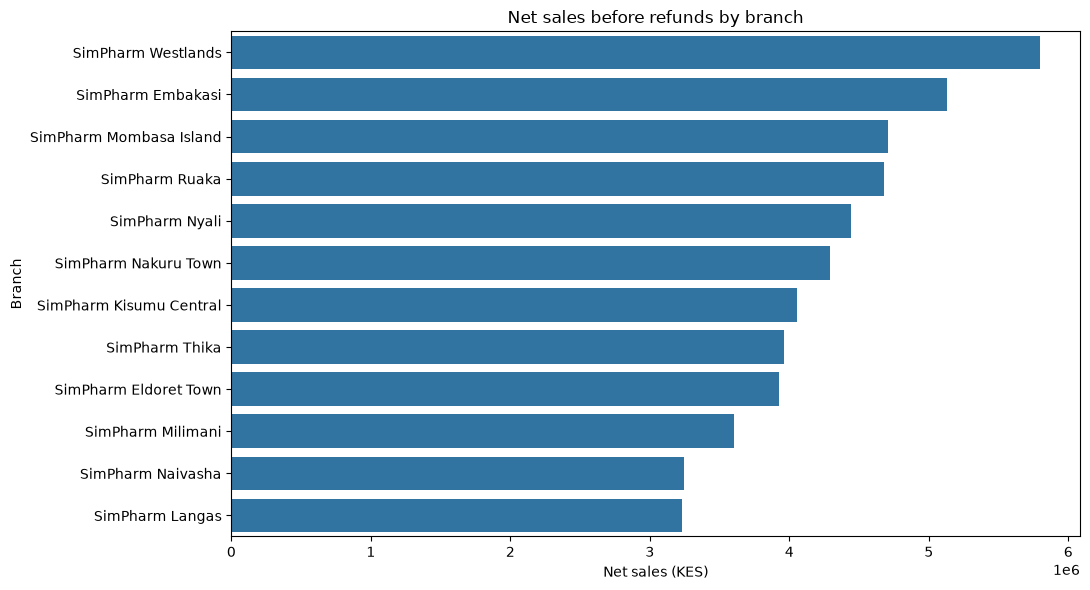

In [12]:
plt.figure(figsize=(11, 6))
sns.barplot(data=branch_performance, x='net_sales', y='store_name')
plt.title('Net sales before refunds by branch')
plt.xlabel('Net sales (KES)')
plt.ylabel('Branch')
plt.tight_layout()
plt.show()

## Sales by county 

In [13]:
trans_df

,transaction_id,line_id,product_id,quantity,unit_price,discount_amount,unit_cost_at_sale,line_gross_amount,line_net_amount,promotion_id,transaction_datetime,store_id,customer_id,payment_method,product_name,category,store_name,county,cost_of_goods_sold,profit_before_refunds
0,TXN0000001,1,P122,1,120.0,0.0,87.71,120.0,120.0,NA,2025-01-01 08:16:00,ST02,CUST02120,Cash,Tetracycline 1% Eye ointment,"Eye, Ear & Nose",SimPharm Embakasi,Nairobi,87.71,32.29
1,TXN0000002,1,P057,1,200.0,0.0,137.06,200.0,200.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,Glimepiride 2 mg Tablets,Diabetes,SimPharm Langas,Uasin Gishu,137.06,62.94
2,TXN0000002,2,P079,2,48.0,0.0,36.69,96.0,96.0,NA,2025-01-01 08:28:00,ST12,CUST04689,M-Pesa,Cetirizine 10 mg Tablets,Respiratory & Allergy,SimPharm Langas,Uasin Gishu,73.38,22.62
3,TXN0000003,1,P056,1,160.0,0.0,125.81,160.0,160.0,NA,2025-01-01 08:59:00,ST06,CUST03048,Insurance,Gliclazide 80 mg Tablets,Diabetes,SimPharm Kisumu Central,Kisumu,125.81,34.19
4,TXN0000004,1,P044,1,145.0,0.0,111.82,145.0,145.0,NA,2025-01-01 09:00:00,ST02,CUST00340,M-Pesa,Losartan 50 mg Tablets,Cardiovascular,SimPharm Embakasi,Nairobi,111.82,33.18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
244267,TXN0099998,2,P091,1,84.0,0.0,58.06,84.0,84.0,NA,2025-12-31 20:52:00,ST10,CUST03884,Cash,Vitamin B complex Tablets,Vitamins & Supplements,SimPharm Ruaka,Kiambu,58.06,25.94
244268,TXN0099999,1,P005,1,110.0,0.0,88.14,110.0,110.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,Ibuprofen 100 mg/5 mL Suspension,Pain & Fever,SimPharm Ruaka,Kiambu,88.14,21.86
244269,TXN0099999,2,P039,2,83.0,0.0,60.86,166.0,166.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,Amlodipine 5 mg Tablets,Cardiovascular,SimPharm Ruaka,Kiambu,121.72,44.28
244270,TXN0099999,3,P150,1,98.0,0.0,66.20,98.0,98.0,NA,2025-12-31 20:56:00,ST10,CUST00386,Cash,Malaria rapid diagnostic test Test kit,First Aid & Medical Supplies,SimPharm Ruaka,Kiambu,66.20,31.80


In [14]:
print(50*'=','sales_by_county',50*'=')
sales_by_county = (
    trans_df.groupby('county', as_index=False)
    .agg(net_sales=('line_net_amount', 'sum'),
         gross_profit_before_refunds=('profit_before_refunds', 'sum'))
    .sort_values('net_sales', ascending=False)
)
display(sales_by_county)



================================================== sales_by_county ==================================================


,county,net_sales,gross_profit_before_refunds
3,Nairobi,10927621.40,2863826.02
2,Mombasa,9151017.85,2383330.71
0,Kiambu,8638952.05,2253456.53
1,Kisumu,7659890.70,1994600.81
4,Nakuru,7537136.45,1971338.22
5,Uasin Gishu,7156746.30,1868670.92


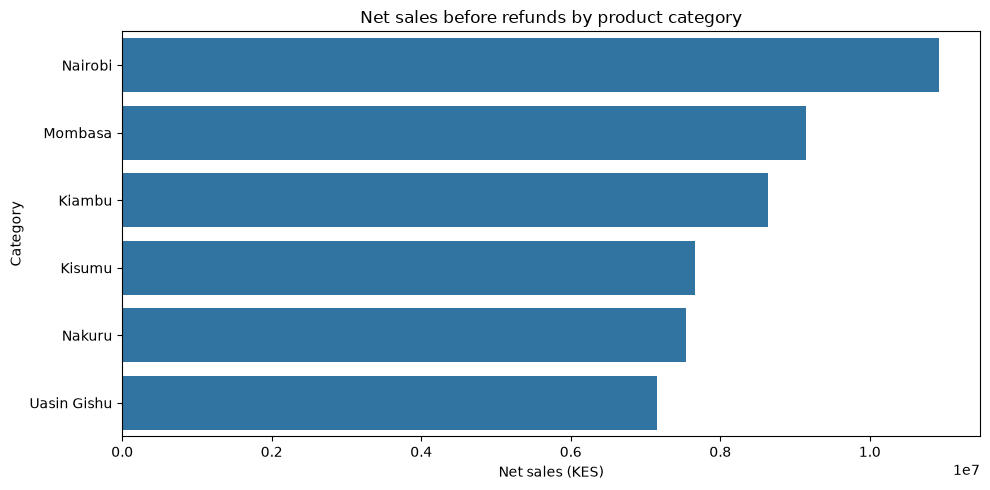

In [15]:
plt.figure(figsize=(10, 5))
sns.barplot(data=sales_by_county, x='net_sales', y='county')
plt.title('Net sales before refunds by product category')
plt.xlabel('Net sales (KES)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

## Sales by month

In [16]:
# trans_df['month_name']=trans_df['transaction_datetime'].dt.month_name()

trans_df['month'] = trans_df['transaction_datetime'].dt.to_period('M').astype(str)

sales_by_month = (
    trans_df.groupby('month', as_index=False)
    .agg(net_sales=('line_net_amount', 'sum'),
         gross_profit_before_refunds=('profit_before_refunds', 'sum'),
         transactions=('transaction_id', 'nunique'))
    .sort_values('month')
)
sales_by_month

,month,net_sales,gross_profit_before_refunds,transactions
0,2025-01,3896269.75,1015621.62,7414
1,2025-02,3511405.85,923629.50,6684
2,2025-03,4026588.85,1059913.15,7747
3,2025-04,4054111.40,1018840.47,7898
4,2025-05,4269824.30,1111763.60,8335
5,2025-06,3928332.10,997792.50,7742
6,2025-07,4401696.80,1164083.33,8570
7,2025-08,4416604.65,1156928.49,8607
8,2025-09,4245643.85,1101012.83,8192
9,2025-10,4747635.70,1250205.64,9059


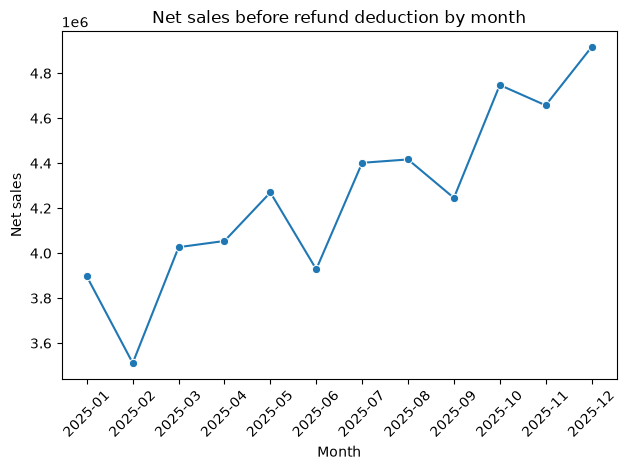

In [17]:
plt.Figure(figsize=[12,8])
sns.lineplot(data=sales_by_month,x='month',y='net_sales',marker = 'o')
plt.title('Net sales before refund deduction by month')
plt.xlabel('Month')
plt.ylabel('Net sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Average basket value and units per transaction

In [18]:
basket_df = (
    trans_df.groupby('transaction_id', as_index=False)
    .agg(
        basket_value=('line_net_amount', 'sum'),
        units_in_basket=('quantity', 'sum'),
        number_of_product_lines=('product_id', 'count'),
        store_id=('store_id', 'first'),
        payment_method=('payment_method', 'first'),
        customer_id=('customer_id', 'first'),
        transaction_datetime=('transaction_datetime', 'first')
    )
)

print('Average basket value (KES):', round(basket_df['basket_value'].mean(), 2))
print('Median basket value (KES):', round(basket_df['basket_value'].median(), 2))
print('Average units per transaction:', round(basket_df['units_in_basket'].mean(), 2))


Average basket value (KES): 518.47
Median basket value (KES): 390.0
Average units per transaction: 3.17


In [19]:
basket_by_branch = (
    basket_df.groupby('store_id', as_index=False)
    .agg(average_basket_value=('basket_value', 'mean'),
         median_basket_value=('basket_value', 'median'),
         average_units=('units_in_basket', 'mean'),
         transactions=('transaction_id', 'count'))
    .merge(stores_df[['store_id', 'store_name']], on='store_id', how='left')
    .sort_values('average_basket_value', ascending=False)
)
print(50*'=','basket by store',50*'=')
display(basket_by_branch)

basket_by_payment = (
    basket_df.groupby('payment_method', as_index=False)
    .agg(average_basket_value=('basket_value', 'mean'),
         transactions=('transaction_id', 'count'))
    .sort_values('average_basket_value', ascending=False)
)
print(50*'=','basket by store',50*'=')
display(basket_by_payment)

================================================== basket by store ==================================================


,store_id,average_basket_value,median_basket_value,average_units,transactions,store_name
9,ST10,549.963973,410.40,3.134792,8502,SimPharm Ruaka
6,ST07,535.616629,405.00,3.212110,8010,SimPharm Nakuru Town
7,ST08,529.665131,401.00,3.216966,6130,SimPharm Naivasha
2,ST03,525.541604,392.00,3.102959,8450,SimPharm Nyali
0,ST01,522.755201,393.00,3.180440,11084,SimPharm Westlands
1,ST02,518.054572,381.00,3.165203,9909,SimPharm Embakasi
10,ST11,515.322481,386.00,3.149305,7622,SimPharm Eldoret Town
5,ST06,514.946764,390.25,3.176545,7879,SimPharm Kisumu Central
3,ST04,510.645197,385.00,3.175629,9224,SimPharm Mombasa Island
11,ST12,502.639843,381.75,3.187733,6424,SimPharm Langas


================================================== basket by store ==================================================


,payment_method,average_basket_value,transactions
1,Cash,521.388827,23610
0,Card,520.455121,9764
2,Insurance,517.711073,5897
3,M-Pesa,517.054827,59233


## Products and categories contributing most sales and profit


In [20]:
revenue_by_product = (
    trans_df.groupby('product_id', as_index=False)
    .agg(total_net_sales=('line_net_amount', 'sum'),
         units_sold=('quantity', 'sum'))
    .merge(products_df[['product_id', 'product_name', 'category']],
           on='product_id', how='left')
    .sort_values('total_net_sales', ascending=False)
)

revenue_by_product.head(10)

,product_id,total_net_sales,units_sold,product_name,category
59,P060,1773372.0,1308,Blood glucose test strips 50 strips Test strips,Diabetes
96,P097,1292677.0,3284,Calcium/Vitamin D3 600 mg/400 IU Tablets,Vitamins & Supplements
83,P084,1261800.0,1716,Beclometasone 100 mcg/dose Inhaler,Respiratory & Allergy
91,P092,1067771.0,2936,Multivitamin Tablets,Vitamins & Supplements
98,P099,1066755.0,1096,Omega-3 fish oil 1000 mg Softgel capsules,Vitamins & Supplements
58,P059,965004.5,989,Human insulin (isophane) 100 IU/mL Injection,Diabetes
57,P058,920040.0,987,Human insulin (soluble) 100 IU/mL Injection,Diabetes
32,P033,912145.5,3993,Artemether/Lumefantrine 20/120 mg Tablets,Antimalarials
43,P044,869615.0,5861,Losartan 50 mg Tablets,Cardiovascular
64,P065,853895.0,5509,Aluminium hydroxide/Magnesium hydroxide Suspen...,Gastrointestinal


In [21]:
profit_by_product = (
    trans_df.groupby('product_id', as_index=False)
    .agg(total_gross_profit_before_refunds=('profit_before_refunds', 'sum'),
         total_net_sales=('line_net_amount', 'sum'),
         units_sold=('quantity', 'sum'))
    .merge(products_df[['product_id', 'product_name', 'category']],
           on='product_id', how='left')
    .sort_values('total_gross_profit_before_refunds', ascending=False)
)
profit_by_product.head(10)

,product_id,total_gross_profit_before_refunds,total_net_sales,units_sold,product_name,category
59,P060,578945.64,1773372.0,1308,Blood glucose test strips 50 strips Test strips,Diabetes
96,P097,339561.68,1292677.0,3284,Calcium/Vitamin D3 600 mg/400 IU Tablets,Vitamins & Supplements
58,P059,265880.40,965004.5,989,Human insulin (isophane) 100 IU/mL Injection,Diabetes
91,P092,259225.96,1067771.0,2936,Multivitamin Tablets,Vitamins & Supplements
82,P083,258327.49,852478.0,1517,Montelukast 10 mg Tablets,Respiratory & Allergy
130,P131,254999.36,851759.0,2949,Levonorgestrel 1.5 mg Tablets,Reproductive Health
57,P058,248840.52,920040.0,987,Human insulin (soluble) 100 IU/mL Injection,Diabetes
32,P033,240123.60,912145.5,3993,Artemether/Lumefantrine 20/120 mg Tablets,Antimalarials
83,P084,234053.28,1261800.0,1716,Beclometasone 100 mcg/dose Inhaler,Respiratory & Allergy
98,P099,231361.88,1066755.0,1096,Omega-3 fish oil 1000 mg Softgel capsules,Vitamins & Supplements


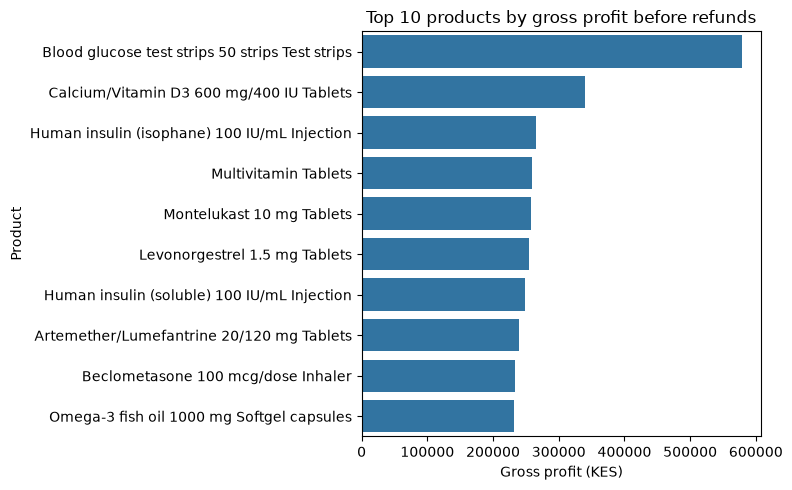

In [22]:
top_profit_products = profit_by_product.head(10).sort_values( 'total_gross_profit_before_refunds', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=top_profit_products,
            x='total_gross_profit_before_refunds', y='product_name')
plt.title('Top 10 products by gross profit before refunds')
plt.xlabel('Gross profit (KES)')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

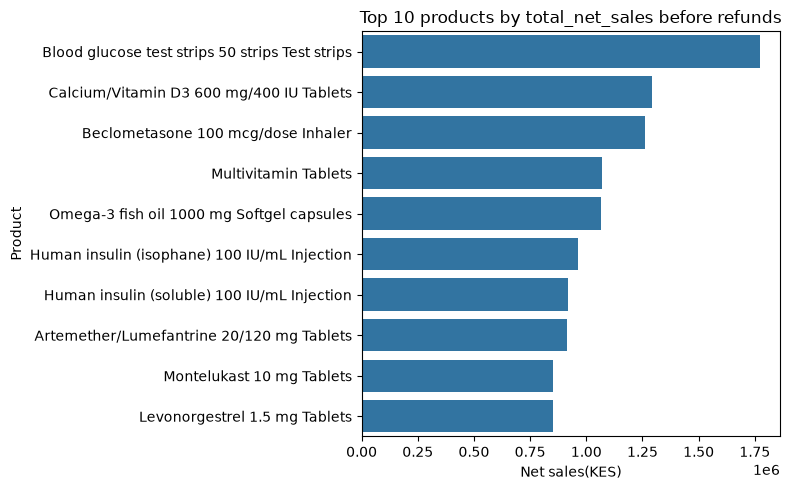

In [29]:
top_profit_products = profit_by_product.head(10).sort_values( 'total_net_sales', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=top_profit_products,
            x='total_net_sales', y='product_name')
plt.title('Top 10 products by total_net_sales before refunds')
plt.xlabel('Net sales(KES)')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

In [23]:
## Product contribution by category
category_contribution = (
    trans_df.groupby('category', as_index=False)
    .agg(net_sales=('line_net_amount', 'sum'),
         gross_profit_before_refunds=('profit_before_refunds', 'sum'))
)

category_contribution['sales_share_pct'] = (
    category_contribution['net_sales'] / category_contribution['net_sales'].sum() * 100
)
category_contribution['profit_share_pct'] = (
    category_contribution['gross_profit_before_refunds'] /
    category_contribution['gross_profit_before_refunds'].sum() * 100
)
category_contribution.sort_values('net_sales', ascending=False)


,category,net_sales,gross_profit_before_refunds,sales_share_pct,profit_share_pct
12,Vitamins & Supplements,7673197.25,1945216.74,15.024461,14.587058
4,Diabetes,6003779.55,1732141.44,11.755667,12.989220
11,Respiratory & Allergy,5691964.45,1432235.84,11.145119,10.740246
0,Antibiotics,5216140.00,1222533.64,10.213434,9.167703
2,Cardiovascular,4704666.85,1245562.02,9.211947,9.340391
3,Dermatology,4497867.75,1199752.00,8.807025,8.996865
7,Gastrointestinal,3989183.65,1076565.39,7.810999,8.073096
6,First Aid & Medical Supplies,3421809.90,921567.03,6.700056,6.910773
9,Pain & Fever,3050071.15,788807.84,5.972175,5.915220
10,Reproductive Health,2625133.30,739808.65,5.140128,5.547779


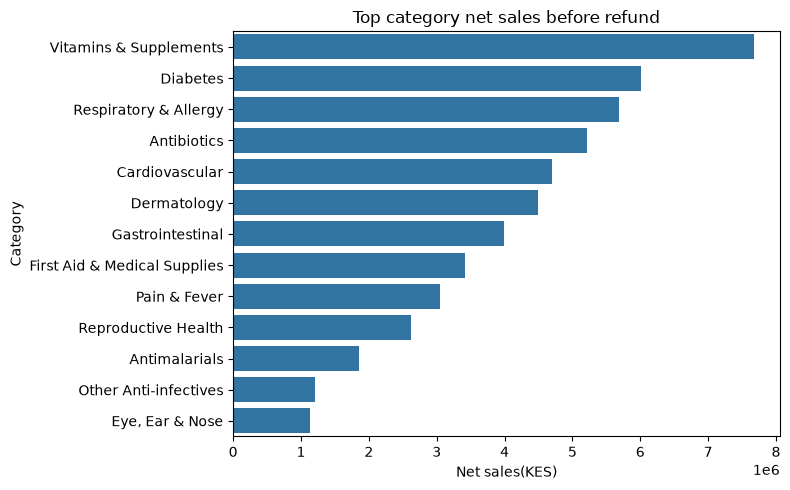

In [27]:
top_profit_products = category_contribution.sort_values( 'net_sales', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=top_profit_products,x='net_sales', y='category')
plt.title('Top category net sales before refund')
plt.xlabel('Net sales(KES)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

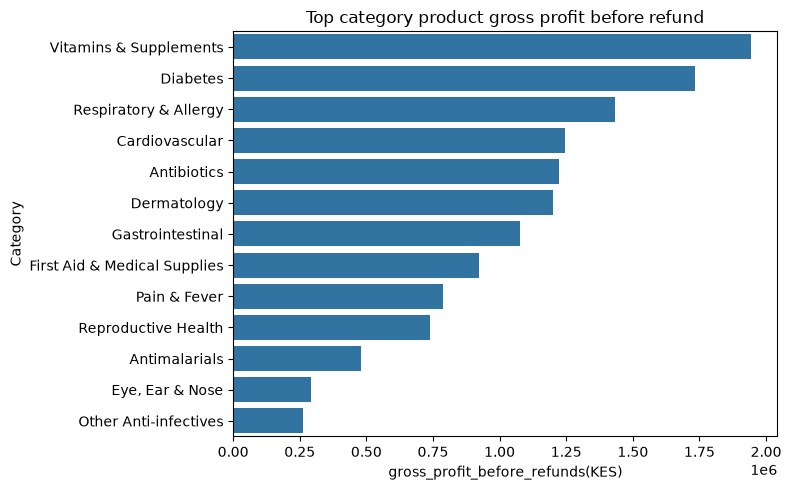

In [31]:
top_profit_products = category_contribution.sort_values( 'gross_profit_before_refunds', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=top_profit_products,x='gross_profit_before_refunds', y='category')
plt.title('Top category product gross profit before refund')
plt.xlabel('gross_profit_before_refunds(KES)')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

## Promotion Comparison

In [35]:
# Daily sales by product
daily_product_sales = (
    trans_df.assign(sale_date=trans_df['transaction_datetime'].dt.normalize())
    .groupby(['sale_date', 'product_id'], as_index=False)
    .agg(units=('quantity', 'sum'),
         net_sales=('line_net_amount', 'sum'),
         profit_before_refunds=('profit_before_refunds', 'sum'))
)

daily_product_sales.head()

,sale_date,product_id,units,net_sales,profit_before_refunds
0,2025-01-01,P001,17,748.0,257.38
1,2025-01-01,P002,4,228.0,50.60
2,2025-01-01,P003,7,315.0,78.54
3,2025-01-01,P004,4,140.0,44.36
4,2025-01-01,P005,5,550.0,109.30


In [62]:
# Choosing one promotion to examine first.
promotion_id_to_check = promotion_df['promotion_id'].iloc[10]

selected_promotion = promotion_df[
    promotion_df['promotion_id'] == promotion_id_to_check
].iloc[0]

# display(promotion_id_to_check, selected_promotion)

In [63]:
# Decide which products are included in the selected promotion
if selected_promotion['promotion_type'] == 'Product-level':
    promotion_products = [selected_promotion['product_id']]
else:
    promotion_products = products_df.loc[
        products_df['category'] == selected_promotion['category'], 'product_id'
    ].tolist()

promotion_start = selected_promotion['start_date'].normalize()
promotion_end = selected_promotion['end_date'].normalize()
promotion_days = (promotion_end - promotion_start).days + 1

prior_start = promotion_start - pd.Timedelta(days=promotion_days)
prior_end = promotion_start - pd.Timedelta(days=1)
post_start = promotion_end + pd.Timedelta(days=1)
post_end = promotion_end + pd.Timedelta(days=promotion_days)

def period_summary(start_date, end_date, period_name):
    period_data = daily_product_sales[
        daily_product_sales['product_id'].isin(promotion_products)
        & (daily_product_sales['sale_date'] >= start_date)
        & (daily_product_sales['sale_date'] <= end_date)
    ]
    return {
        'period': period_name,
        'start_date': start_date,
        'end_date': end_date,
        'units_sold': period_data['units'].sum(),
        'net_sales': period_data['net_sales'].sum(),
        'profit_before_refunds': period_data['profit_before_refunds'].sum(),
        'days_in_period': (end_date - start_date).days + 1
    }

promotion_comparison = pd.DataFrame([
    period_summary(prior_start, prior_end, 'Before'),
    period_summary(promotion_start, promotion_end, 'During'),
    period_summary(post_start, post_end, 'After')
])

promotion_comparison['units_per_day'] = (
    promotion_comparison['units_sold'] / promotion_comparison['days_in_period']
)
promotion_comparison['profit_per_day'] = (
    promotion_comparison['profit_before_refunds'] /
    promotion_comparison['days_in_period']
)

display(promotion_comparison)
display(selected_promotion)

,period,start_date,end_date,units_sold,net_sales,profit_before_refunds,days_in_period,units_per_day,profit_per_day
0,Before,2025-03-02,2025-03-11,46,13892.75,4429.63,10,4.6,442.963
1,During,2025-03-12,2025-03-21,51,15335.00,4843.28,10,5.1,484.328
2,After,2025-03-22,2025-03-31,36,10980.00,3574.08,10,3.6,357.408


promotion_id                             PROMO011
promotion_name    Lancets 100 lancets - KES 5 off
promotion_type                      Product-level
product_id                                   P061
category                             Not Provided
start_date                    2025-03-12 00:00:00
end_date                      2025-03-21 00:00:00
discount_type                        Fixed amount
discount_value                                5.0
Name: 10, dtype: object

**something worth noting:**

**I selected several products on promotion and compared with before**

**and after promition and its noticable theat during the promition periods the products are selling more**

# Customer Intelligence

### Repeate rate and purchase frequency

In [64]:
# Exclude missing and placeholder customer IDs
identified_transactions = transactions_complete_df[
    transactions_complete_df['customer_id'].notna()
    & (transactions_complete_df['customer_id'] != 'Not Provided')
].copy()

# Count transactions for each identified customer
transactions_per_customer = (
    identified_transactions.groupby('customer_id')['transaction_id']
    .nunique()
    .reset_index(name='transaction_count')
    .sort_values('transaction_count', ascending=False)
)

display(transactions_per_customer.head(10))

,customer_id,transaction_count
4958,CUST04965,156
2935,CUST02940,152
2293,CUST02298,149
4303,CUST04310,149
3894,CUST03901,116
2308,CUST02313,107
1280,CUST01285,105
5064,CUST05071,103
2717,CUST02722,95
1487,CUST01492,93


In [66]:
total_identified_customers = transactions_per_customer['customer_id'].nunique()
repeat_customers = (transactions_per_customer['transaction_count'] >= 2).sum()

repeat_rate_pct = (
    repeat_customers / total_identified_customers * 100
    if total_identified_customers else np.nan
)

print('Identified customers with a completed purchase:', total_identified_customers)
print('Customers with 2 or more transactions:', repeat_customers)
print(f'Repeat customer rate: {repeat_rate_pct:.2f}%')
print('Average transactions per customer:',
      round(transactions_per_customer['transaction_count'].mean(), 2))

Identified customers with a completed purchase: 7989
Customers with 2 or more transactions: 7348
Repeat customer rate: 91.98%
Average transactions per customer: 9.87


**Something worth noting:**
- This are the top ten frequent customers ids :
```Top_ten_clients=['CUST04965','CUST02940','CUST02298','CUST04310','CUST03901','CUST02313','CUST01285','CUST05071','CUST02722','CUST01492']```

|customer_id|Transaction count|
|:-----|:-------|
|CUST04965|156|
|CUST02940|152|
|CUST02298|149|
|CUST04310|149|
|CUST03901|116|
|CUST02313|107|
|CUST01285|105|
|CUST05071|103|
|CUST02722|95|
|CUST01492|93|

## customers generating the highest profits and sales

In [69]:
# Join customer IDs onto the product-line sales data
identified_sales = trans_df[
    trans_df['customer_id'].notna()
    & (trans_df['customer_id'] != 'Not Provided')
].copy()

# Highest revenue-generating customers
top_revenue_generating_clients = (
    identified_sales.groupby('customer_id', as_index=False)
    .agg(total_net_sales=('line_net_amount', 'sum'))
    .sort_values('total_net_sales', ascending=False)
)

# Highest profit-generating customers (before refunds)
top_profit_generating_clients = (
    identified_sales.groupby('customer_id', as_index=False)
    .agg(total_profit_before_refunds=('profit_before_refunds', 'sum')).round(2)
    .sort_values('total_profit_before_refunds', ascending=False)
)

print('Top 10 customers by net sales')
display(top_revenue_generating_clients.head(10))

print('Top 10 customers by profit before refunds')
display(top_profit_generating_clients.head(10))

Top 10 customers by net sales


,customer_id,total_net_sales
2935,CUST02940,95101.40
3894,CUST03901,85344.50
4303,CUST04310,82341.75
2293,CUST02298,75791.60
4958,CUST04965,70388.90
5064,CUST05071,59081.70
2335,CUST02340,58611.75
2308,CUST02313,55156.80
5410,CUST05417,53515.55
3763,CUST03769,51240.80


Top 10 customers by profit before refunds


,customer_id,total_profit_before_refunds
2935,CUST02940,25705.85
3894,CUST03901,22027.69
4303,CUST04310,21652.84
2293,CUST02298,19410.92
4958,CUST04965,18613.10
2335,CUST02340,15281.60
5064,CUST05071,15017.72
2308,CUST02313,14449.45
3763,CUST03769,13820.22
5162,CUST05169,13009.58


### Checking what the top 10 frequent customers are genarating as profits and as revenue.

In [72]:
top_freq_customers=['CUST04965','CUST02940','CUST02298','CUST04310','CUST03901','CUST02313','CUST01285','CUST05071','CUST02722','CUST01492']

top_freq_customers_revenue=top_revenue_generating_clients[top_revenue_generating_clients['customer_id'].isin(top_freq_customers)]

top_freq_customers_profits = top_profit_generating_clients[top_profit_generating_clients['customer_id'].isin(top_freq_customers)]

display(top_freq_customers_profits)

display(top_freq_customers_revenue)


,customer_id,total_profit_before_refunds
2935,CUST02940,25705.85
3894,CUST03901,22027.69
4303,CUST04310,21652.84
2293,CUST02298,19410.92
4958,CUST04965,18613.10
5064,CUST05071,15017.72
2308,CUST02313,14449.45
1487,CUST01492,12357.12
1280,CUST01285,11572.24
2717,CUST02722,10087.60


,customer_id,total_net_sales
2935,CUST02940,95101.40
3894,CUST03901,85344.50
4303,CUST04310,82341.75
2293,CUST02298,75791.60
4958,CUST04965,70388.90
5064,CUST05071,59081.70
2308,CUST02313,55156.80
1487,CUST01492,45987.00
1280,CUST01285,45029.50
2717,CUST02722,39760.50


### Comparing sales profits and transaction counts

In [73]:
customer_sales_profit = top_revenue_generating_clients.merge(
    top_profit_generating_clients,
    on='customer_id',
    how='outer'
).merge(
    transactions_per_customer,
    on='customer_id',
    how='left'
).sort_values('total_net_sales', ascending=False)

display(customer_sales_profit.head(10))

,customer_id,total_net_sales,total_profit_before_refunds,transaction_count
2935,CUST02940,95101.40,25705.85,152
3894,CUST03901,85344.50,22027.69,116
4303,CUST04310,82341.75,21652.84,149
2293,CUST02298,75791.60,19410.92,149
4958,CUST04965,70388.90,18613.10,156
5064,CUST05071,59081.70,15017.72,103
2335,CUST02340,58611.75,15281.60,83
2308,CUST02313,55156.80,14449.45,107
5410,CUST05417,53515.55,12168.98,59
3763,CUST03769,51240.80,13820.22,51


**Something worth noting**

**Not all clients with high frequent transactions also appeares to the**

**top clients genearting either higher profiit or higher revenue** 

## Customer value analysis (RFM)

RFM stands for:
- **Recency:** how many days since the customer's last purchase
- **Frequency:** how many completed transactions they made
- **Monetary value:** how much net sales they generated

In [84]:
# Add the date of each completed transaction to customer sales
customer_value = (
    identified_sales.groupby('customer_id', as_index=False)
    .agg(
        total_net_sales=('line_net_amount', 'sum'),
        total_profit_before_refunds=('profit_before_refunds', 'sum'),
        transaction_count=('transaction_id', 'nunique'),
        last_purchase=('transaction_datetime', 'max'),
        first_purchase=('transaction_datetime', 'min'))
)
customer_value=customer_value.round({'total_net_sales':2,
                                     'total_profit_before_refunds':2})

customer_value

,customer_id,total_net_sales,total_profit_before_refunds,transaction_count,last_purchase,first_purchase
0,CUST00001,23470.75,6442.11,41,2025-11-26 17:29:00,2025-01-14 17:49:00
1,CUST00002,4091.50,1039.89,11,2025-12-31 09:16:00,2025-03-12 14:29:00
2,CUST00003,17638.45,4489.41,30,2025-12-27 13:10:00,2025-01-10 15:23:00
3,CUST00004,1347.00,396.17,4,2025-10-13 18:43:00,2025-03-23 17:48:00
4,CUST00005,5455.65,1434.39,9,2025-12-24 09:46:00,2025-03-17 08:00:00
...,...,...,...,...,...,...
7984,CUST07996,1175.00,333.19,1,2025-12-31 12:54:00,2025-12-31 12:54:00
7985,CUST07997,77.00,17.81,1,2025-12-31 14:54:00,2025-12-31 14:54:00
7986,CUST07998,145.00,43.01,1,2025-12-31 16:11:00,2025-12-31 16:11:00
7987,CUST07999,754.00,202.63,1,2025-12-31 15:09:00,2025-12-31 15:09:00


In [85]:
# Measure recency from the last date in the dataset
analysis_date = identified_sales['transaction_datetime'].max().normalize()

customer_value['days_since_last_purchase'] = (
    analysis_date - customer_value['last_purchase'].dt.normalize()
).dt.days

customer_value['days_between_first_and_last'] = (
    customer_value['last_purchase'].dt.normalize()
    - customer_value['first_purchase'].dt.normalize()
).dt.days

customer_value = customer_value.sort_values('total_net_sales', ascending=False)

customer_value.head(30)

,customer_id,total_net_sales,total_profit_before_refunds,transaction_count,last_purchase,first_purchase,days_since_last_purchase,days_between_first_and_last
2935,CUST02940,95101.40,25705.85,152,2025-12-30 18:16:00,2025-01-01 18:21:00,1,363
3894,CUST03901,85344.50,22027.69,116,2025-12-24 13:57:00,2025-01-11 18:27:00,7,347
4303,CUST04310,82341.75,21652.84,149,2025-12-30 15:33:00,2025-01-02 11:49:00,1,362
2293,CUST02298,75791.60,19410.92,149,2025-12-29 11:16:00,2025-01-04 16:39:00,2,359
4958,CUST04965,70388.90,18613.10,156,2025-12-28 11:50:00,2025-01-01 14:53:00,3,361
5064,CUST05071,59081.70,15017.72,103,2025-12-26 11:57:00,2025-01-06 11:06:00,5,354
2335,CUST02340,58611.75,15281.60,83,2025-12-30 11:26:00,2025-01-09 18:37:00,1,355
2308,CUST02313,55156.80,14449.45,107,2025-12-30 10:16:00,2025-01-01 10:29:00,1,363
5410,CUST05417,53515.55,12168.98,59,2025-12-27 12:15:00,2025-01-03 13:58:00,4,358
3763,CUST03769,51240.80,13820.22,51,2025-12-19 20:41:00,2025-01-08 11:30:00,12,345


### Checking how much of identified-customer sales comes from the top 10% of customers

In [87]:
# Sort customers by their total sales
customer_value_sorted = customer_value.sort_values('total_net_sales', ascending=False).copy()

#Calculating  how many customers make up the top 10%
number_top_10_pct = max(1, int(np.ceil(len(customer_value_sorted) * 0.10)))

#Calculating the percentage of sales generated by that group
top_10_pct_sales_share = ((customer_value_sorted.head(number_top_10_pct)['total_net_sales'].sum())
    / (customer_value_sorted['total_net_sales'].sum()) * 100)

print('Number of identified customers:', len(customer_value_sorted))
print('Customers in the top 10% group:', number_top_10_pct)
print(f'Share of identified-customer sales generated by this group: {top_10_pct_sales_share:.2f}%')

Number of identified customers: 7989
Customers in the top 10% group: 799
Share of identified-customer sales generated by this group: 36.44%


## Customers who may have lapsed

This is to find customers who have not purchased recently.Am going to use a fixed 60-day rule. 

For clients who have not returneed after 60 days is a good reason to findout why but it also doesnot mean they disapeared

Because the dataset ends in 2025, customers who purchased near the end of the year had less time to return.

In [89]:
customer_value['customer_status_60_days'] = np.where(
    customer_value['days_since_last_purchase'] >= 60,
    'Potentially lapsed',
    'Recent purchase')

lapse_summary = (
    customer_value['customer_status_60_days']
    .value_counts()
    .rename_axis('customer_status')
    .reset_index(name='number_of_customers')
)

lapse_summary

,customer_status,number_of_customers
0,Recent purchase,5630
1,Potentially lapsed,2359


In [92]:
potentially_lapsed_customers = customer_value[customer_value['customer_status_60_days'] == 'Potentially lapsed'].sort_values('total_net_sales', ascending=False)

potentially_lapsed_customers=(potentially_lapsed_customers[['customer_id', 'total_net_sales', 'transaction_count','last_purchase', 'days_since_last_purchase']]
    .sort_values('days_since_last_purchase', ascending=False))
potentially_lapsed_customers.head(50)

,customer_id,total_net_sales,transaction_count,last_purchase,days_since_last_purchase
4523,CUST04530,88.00,1,2025-01-02 13:31:00,363
5628,CUST05635,405.00,1,2025-01-03 12:29:00,362
1430,CUST01435,1291.00,1,2025-01-03 18:36:00,362
6571,CUST06579,267.00,1,2025-01-07 14:18:00,358
5123,CUST05130,1665.25,1,2025-01-07 11:20:00,358
6577,CUST06585,58.00,1,2025-01-07 10:49:00,358
510,CUST00513,615.00,1,2025-01-08 11:07:00,357
1302,CUST01307,216.00,1,2025-01-10 20:32:00,355
4854,CUST04861,1331.00,1,2025-01-10 19:28:00,355
7554,CUST07563,320.00,1,2025-01-11 18:13:00,354


In [94]:
potentially_lapsed_customers.describe().T

,count,mean,min,25%,50%,75%,max,std
total_net_sales,2359.0,2312.081136,31.0,810.5,1729.0,3104.95,18335.25,2117.575519
transaction_count,2359.0,4.233574,1.0,2.0,3.0,6.0,36.0,3.283618
last_purchase,2359,2025-08-23 11:43:14.497668,2025-01-02 13:31:00,2025-07-22 19:47:00,2025-09-15 10:48:00,2025-10-15 02:23:30,2025-11-01 19:48:00,NaN
days_since_last_purchase,2359.0,130.125477,60.0,77.5,107.0,162.0,363.0,68.556914


**Something worth noting the clients with the highest days_since_last_purchase also have the** 

**lowest number of transactions and generatatee the lowest revenue and profits**